# Phần 3: Kỹ Thuật Đặc Trưng Nghiệp Vụ Chuyên Sâu (Feature Engineering & Tet Cycles)
## Xây Dựng Ma Trận Đặc Trưng 10 Giai Đoạn Tết, Tương Tác Khuyến Mãi Đa Tầng & Thời Tiết Phi Tuyến

---

### 1. Phân Tích Chuyên Sâu Cách Làm:
Dựa trên các phát hiện so sánh ở Phần 2, Phần 3 tập trung xây dựng các đặc trưng toán học phản ánh đúng cơ chế sinh dữ liệu (DGP):
1. **Phân kỳ Tết 10 giai đoạn (Tet 10-Phase Segmentation):** Chia chu kỳ Tết quanh mốc Mùng 1 thành 10 giai đoạn riêng biệt (pre-tet, cúng Ông Táo 23 tháng Chạp, cận Tết, mùng 1-2 Tết, hậu Tết).
2. **Tương tác ngày lễ đặc thù năm 2026:**
   - Ngày Lễ Tình Nhân Valentine `14/02/2026` rơi vào ngày **27 tháng Chạp** (rất cận Tết).
   - Ngày Quốc Tế Phụ Nữ `08/03/2026` và Tết Dương Lịch `01/01/2026`.
3. **Tương tác khuyến mãi đa chiều:**
   - `promo_weekend`: Khuyến mãi vào thứ 7, Chủ Nhật bùng nổ mạnh hơn ngày thường.
   - `promo_{store_type}`: Quán Trung tâm thương mại (`mall`) hưởng lợi khuyến mãi lớn hơn quán văn phòng (`office`).
4. **Phân tách phi tuyến thời tiết:**
   - Mưa nhẹ ($0 - 15	ext{mm}$) chỉ gây cản trở nhẹ, nhưng mưa ngập ($> 15	ext{mm}$) làm sụt giảm nghiêm trọng các quán mặt phố (`street`).

In [1]:
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

for p in [os.path.abspath(".."), os.path.abspath("."), os.path.abspath("../..")]:
    if os.path.exists(os.path.join(p, "data")):
        DATA_DIR = os.path.join(p, "data")
    if p not in sys.path and os.path.exists(os.path.join(p, "src")):
        sys.path.insert(0, p)

from src.cleaning import clean_train, clean_stores, clean_weather, clean_holidays
from src.features import enrich_data, build_shared_matrix

stores_raw = pd.read_csv(os.path.join(DATA_DIR, "stores.csv"))
weather_raw = pd.read_csv(os.path.join(DATA_DIR, "weather.csv"))
holidays_raw = pd.read_csv(os.path.join(DATA_DIR, "holidays.csv"))
train_raw = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))

stores_c = clean_stores(stores_raw)
weather_c = clean_weather(weather_raw, stores_c["city"].unique())
nat_hol, evt_hol, tet_dates = clean_holidays(holidays_raw)
train_c, _ = clean_train(train_raw, stores_c)

# 1. Tạo các đặc trưng nâng cao
train_enriched = enrich_data(train_c, stores_c, weather_c, nat_hol, evt_hol, tet_dates)
X_shared = build_shared_matrix(train_enriched)

print(f"Kích thước ma trận đặc trưng hệ thống: {X_shared.shape}")
print(f"Số lượng đặc trưng tạo lập: {X_shared.shape[1]} đặc trưng")
display(X_shared.head(3))

Kích thước ma trận đặc trưng hệ thống: (26500, 131)
Số lượng đặc trưng tạo lập: 131 đặc trưng


,st_dow_mall_0,st_dow_mall_1,st_dow_mall_2,st_dow_mall_3,st_dow_mall_4,st_dow_mall_5,st_dow_mall_6,st_dow_office_0,st_dow_office_1,st_dow_office_2,...,temp_hn_residential,temp_hcm_residential,promo_street,rain_lin_street,temp_hn_street,temp_hcm_street,promo_university,rain_lin_university,temp_hn_university,temp_hcm_university
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.81,-0.0,0.0,0.0,-0.00,-0.0,0.0,0.0,-0.0,-0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,-0.00,-0.0,0.0,0.0,-0.00,-0.0,0.0,0.0,-0.0,-0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.00,-0.0,0.0,0.0,-0.81,-0.0,0.0,0.0,-0.0,-0.0


### 2. Trực Quan Hóa Tác Động Từng Giai Đoạn Tết Lên Doanh Thu

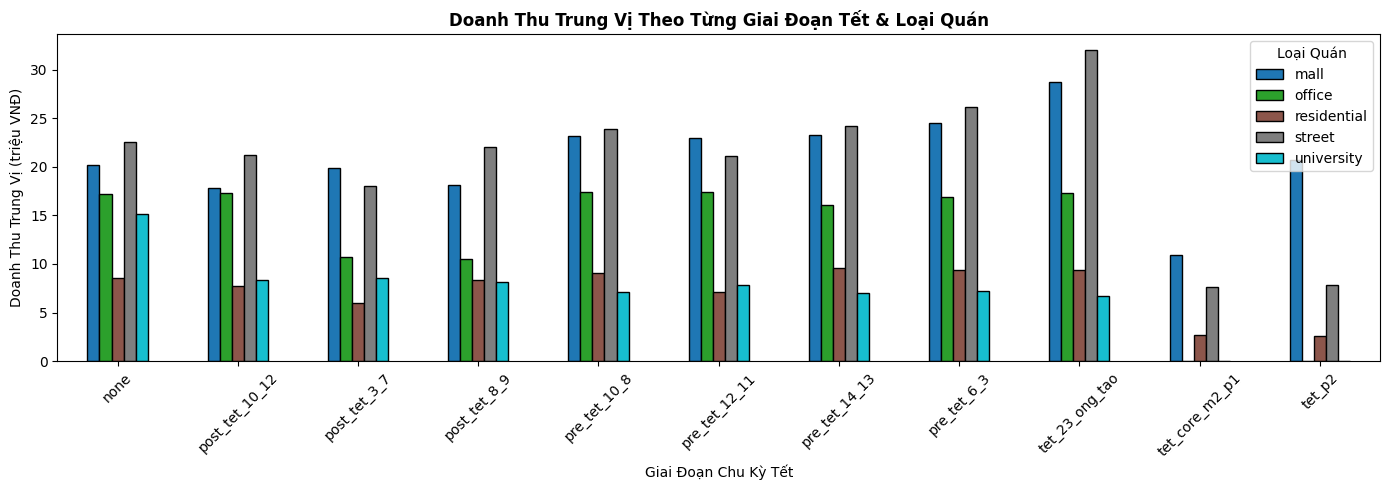

In [2]:
tet_impact = train_enriched.groupby(["tet_phase", "store_type"])["revenue"].median().unstack()
fig, ax = plt.subplots(figsize=(14, 5))
tet_impact.plot(kind="bar", ax=ax, colormap="tab10", edgecolor="black")
ax.set_title("Doanh Thu Trung Vị Theo Từng Giai Đoạn Tết & Loại Quán", fontweight="bold")
ax.set_ylabel("Doanh Thu Trung Vị (triệu VNĐ)")
ax.set_xlabel("Giai Đoạn Chu Kỳ Tết")
plt.xticks(rotation=45)
ax.legend(title="Loại Quán")
plt.tight_layout()
plt.show()